# Ingatlanhirdetés adatok — EDA és előfeldolgozás

Ez a notebook a `plan.md` **3. (Alternatív / kiegészítő irányok)** és **4. (Előfeldolgozási terv)** pontjait valósítja meg:

- feltárjuk az adatokat úgy, hogy el tudjuk dönteni, melyik modellezési irány (regresszió / osztályozás / klaszterezés) a legéletképesebb a jelenlegi adatmennyiséggel,
- majd elvégezzük a tervezett előfeldolgozási lépéseket (hiányzó értékek, location-parszolás, transzformációk, kódolás).

**Fontos:** az adatgyűjtés még folyamatban van, a `data/properties.csv` jelenleg csak egy korai pillanatkép. Ez a notebook úgy készül, hogy a cellák újrafuttathatók legyenek, ha bővül az adat.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (8, 4)

df = pd.read_csv("../data/properties.csv")
print("Betöltött sorok, oszlopok:", df.shape)

# A fetch/parse pipeline időről időre újra letölti/feldolgozza ugyanazt a
# hirdetést (ha a linkje többször is bekerül a letöltési sorba) — emiatt
# ugyanaz a (portal, property_id) pár több sorban is szerepelhet, azonos
# tartalommal, csak más scraped_at időponttal. Ezeknél a legfrissebb
# pillanatképet tartjuk meg, a korábbi duplikátumokat eldobjuk.
dup_mask = df.duplicated(subset=["portal", "property_id"], keep=False)
print(f"Duplikált (portal, property_id) párt tartalmazó sorok: {dup_mask.sum()}")
df = (
    df.sort_values("scraped_at")
    .drop_duplicates(subset=["portal", "property_id"], keep="last")
    .reset_index(drop=True)
)
print("Sorok, oszlopok deduplikálás után:", df.shape)
df.head()


Betöltött sorok, oszlopok: (1615, 16)
Duplikált (portal, property_id) párt tartalmazó sorok: 170
Sorok, oszlopok deduplikálás után: (1526, 16)


,url,portal,property_id,property_type,condition,title,price,currency,area_sqm,rooms,location,city,lat,lon,scraped_at,source_file
0,https://www.oc.hu/ingatlanok/H527040,oc.hu,H527040,lakas,kivalo,H527040,61900000,HUF,46,NaN,"Budapest XIV. kerület, Rákosfalva",Budapest XIV. kerület,47.506887,19.146222,2026-11-12T20:41:23+00:00,data/html/oc_hu/361e53ed1e7dbc20.html
1,https://www.oc.hu/ingatlanok/H527114,oc.hu,H527114,lakas,jo,H527114,74900000,HUF,51,NaN,"Budapest XIV. kerület, Herminamező",Budapest XIV. kerület,47.518684,19.099723,2026-11-12T20:41:24+00:00,data/html/oc_hu/d16d091bb7908d3c.html
2,https://www.oc.hu/ingatlanok/H526898,oc.hu,H526898,lakas,jo,H526898,64900000,HUF,52,NaN,"Budapest III. kerület, Békásmegyer",Budapest III. kerület,47.599413,19.054996,2026-11-13T07:34:50+00:00,data/html/oc_hu/a232d2fd703b1276.html
3,https://www.oc.hu/ingatlanok/H526048,oc.hu,H526048,lakas,jo,H526048,36000000,HUF,60,NaN,"Szekszárd, Szekszárd, Erkel Ferenc utca",Szekszárd,46.352020,18.696683,2026-11-13T07:34:51+00:00,data/html/oc_hu/6122815785b8a09f.html
4,https://www.oc.hu/ingatlanok/H526497,oc.hu,H526497,lakas,kivalo,H526497,149900000,HUF,116,NaN,"Budapest XVI. kerület, Mátyásföld",Budapest XVI. kerület,47.505783,19.208640,2026-11-13T07:42:23+00:00,data/html/oc_hu/3b4588e5c23fee19.html


## 3. Alternatív / kiegészítő irányok — melyik életképes a jelenlegi adattal?

A `plan.md` négy irányt vázolt fel:

- **A) Regresszió** — ár vagy ár/m² becslés (fő javaslat)
- **B) Osztályozás** — `property_type` predikció
- **C) Klaszterezés** — földrajzi árszegmensek
- **D) Anomália detektálás** — alul-/túlárazott hirdetések (stretch goal)

Mielőtt belemegyünk a modellezésbe, megnézzük: melyik irányhoz van **elég és elég jó minőségű** adat jelenleg.


property_type
lakas        698
haz          678
telek         80
nyaralo       49
sorhaz        20
beruhazas      1
Name: count, dtype: int64


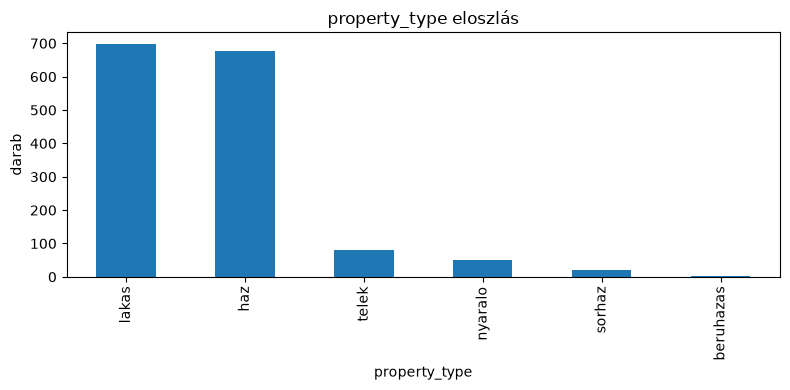

In [2]:
# B) Osztályozáshoz: property_type eloszlás -> van-e elég minta minden osztályhoz?
type_counts = df["property_type"].value_counts()
print(type_counts)

type_counts.plot(kind="bar", title="property_type eloszlás")
plt.ylabel("darab")
plt.tight_layout()
plt.show()


In [3]:
# Hiányzó értékek áttekintése - oszloponként, és kulcs oszlopok property_type / portal szerint
missing_overview = df.isna().mean().sort_values(ascending=False) * 100
print("Hiányzó érték arány (%) oszloponként:")
print(missing_overview.round(1))

print("\nHiányzó 'rooms' arány (%) property_type szerint (C) és B) relevancia):")
print((df.groupby("property_type")["rooms"].apply(lambda s: s.isna().mean() * 100)).round(1))

print("\nHiányzó 'lat' arány (%) portal szerint (C) klaszterezés relevancia):")
print((df.groupby("portal")["lat"].apply(lambda s: s.isna().mean() * 100)).round(1))


Hiányzó érték arány (%) oszloponként:
rooms            14.5
title             2.4
property_id       0.0
url               0.0
property_type     0.0
condition         0.0
price             0.0
portal            0.0
currency          0.0
area_sqm          0.0
location          0.0
city              0.0
lat               0.0
lon               0.0
scraped_at        0.0
source_file       0.0
dtype: float64

Hiányzó 'rooms' arány (%) property_type szerint (C) és B) relevancia):
property_type
beruhazas    100.0
haz            8.0
lakas         10.5
nyaralo       28.6
sorhaz         0.0
telek        100.0
Name: rooms, dtype: float64

Hiányzó 'lat' arány (%) portal szerint (C) klaszterezés relevancia):
portal
dh.hu               0.0
ingatlanbazar.hu    0.0
jofogas.hu          0.0
oc.hu               0.0
zenga.hu            0.0
Name: lat, dtype: float64


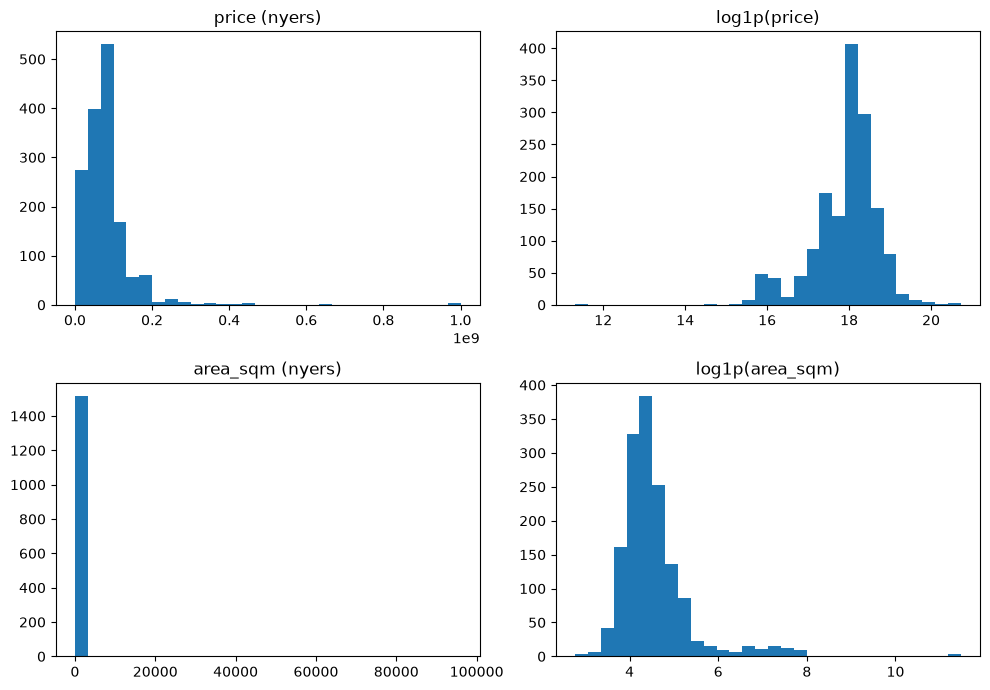

price leíró statisztika:
count    1.526000e+03
mean     7.934713e+07
std      6.907561e+07
min      8.200000e+04
25%      3.990000e+07
50%      7.082313e+07
75%      9.600000e+07
max      1.000000e+09
Name: price, dtype: float64

area_sqm leíró statisztika:
count     1526.000000
mean       374.619921
std       4307.530898
min         15.000000
25%         58.000000
50%         78.000000
75%        116.000000
max      95989.000000
Name: area_sqm, dtype: float64


In [4]:
# A) Regresszióhoz: price és area_sqm eloszlása -> erős jobbra elnyúlás, log-transzformáció indokolt?
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

axes[0, 0].hist(df["price"], bins=30)
axes[0, 0].set_title("price (nyers)")

axes[0, 1].hist(np.log1p(df["price"]), bins=30)
axes[0, 1].set_title("log1p(price)")

axes[1, 0].hist(df["area_sqm"], bins=30)
axes[1, 0].set_title("area_sqm (nyers)")

axes[1, 1].hist(np.log1p(df["area_sqm"]), bins=30)
axes[1, 1].set_title("log1p(area_sqm)")

plt.tight_layout()
plt.show()

print("price leíró statisztika:")
print(df["price"].describe())
print("\narea_sqm leíró statisztika:")
print(df["area_sqm"].describe())


Koordinátával rendelkező sorok: 1526 / 1526 (100.0%)


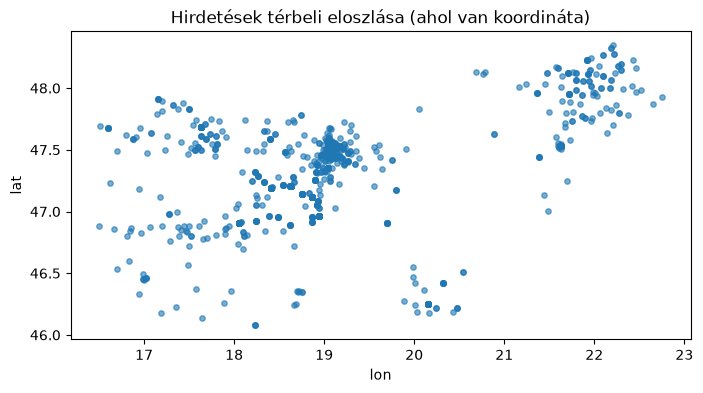

In [5]:
# C) Klaszterezéshez: mennyi sor rendelkezik érvényes lat/lon-nal?
has_coords = df["lat"].notna() & df["lon"].notna()
print(f"Koordinátával rendelkező sorok: {has_coords.sum()} / {len(df)} ({has_coords.mean()*100:.1f}%)")

plt.scatter(df.loc[has_coords, "lon"], df.loc[has_coords, "lat"], s=15, alpha=0.6)
plt.xlabel("lon")
plt.ylabel("lat")
plt.title("Hirdetések térbeli eloszlása (ahol van koordináta)")
plt.show()


### Következtetés (3. pont)

- **A) Regresszió marad a fő irány**: `price`/`area_sqm` minden sorra megvan, a log-transzformáció láthatóan segít a torzított eloszláson.
- **B) Osztályozás** csak kiegészítő lehet: a `beruhazas` osztály 1 elemes, ez nélkül (haz/lakas/telek/nyaralo/sorhaz) 5 osztály fér bele, immár a `sorhaz` is érdemi (nem 1 elemes) mintaszámmal.
- **C) Klaszterezés** mára a koordináták majdnem teljes lefedettsége miatt (a `city` mezőre eső geokódolási fallback következtében) a teljes adatkészleten futtatható, nem csak egy szűkebb részhalmazon.
- **D) Anomália detektálás** csak az A) modell felépítése után értelmezhető (reziduum alapú), ezért ezt később, a modellezési notebookban érdemes megcsinálni.

## 4. Előfeldolgozási terv megvalósítása

Az alábbi lépések a `plan.md` 4. pontját követik: hiányzó értékek kezelése, `location`/`city` feldolgozás, transzformációk, kódolás. A cél egy `df_prep` DataFrame, ami már közvetlenül modellezhető.


### 4.1 Alapok: oszlopok szűkítése, konstans oszlop elhagyása

In [6]:
# Egy hirdetésnél (oc.hu, H525602) a currency=EUR, miközben az ár nagyságrendje
# (55 m²-es budapesti lakás ~86 millió "EUR"-ért) egyértelműen HUF-ra utal — ez
# valószínűleg a portál GTM dataLayer-éből adódó adatminőségi hiba (lásd README
# "Ismert korlátozás" / a dokumentáció Adatkészlet szekciója). Mivel egyetlen
# sorról van szó és a helyes árat nem tudjuk megbízhatóan rekonstruálni, kiszűrjük.
non_huf = df[df["currency"] != "HUF"]
print(f"Nem HUF pénznemű sorok száma: {len(non_huf)} (kiszűrve a modellezésből)")
print(non_huf[["url", "portal", "price", "currency", "area_sqm"]])

df_prep = df[df["currency"] == "HUF"].drop(columns=["currency"]).copy()
print("\ncurrency eldobva (a megmaradt sorokban mindig HUF, nem hordoz infót)")
df_prep.shape

Nem HUF pénznemű sorok száma: 1 (kiszűrve a modellezésből)
                                      url portal     price currency  area_sqm
202  https://www.oc.hu/ingatlanok/H525602  oc.hu  86126910      EUR        55

currency eldobva (a megmaradt sorokban mindig HUF, nem hordoz infót)


(1525, 15)

### 4.2 Hiányzó `rooms` kezelése

- `telek`-nél a hiány logikus (földterületnek nincs szobaszáma) → `0`.
- a többi típusnál mediánnal pótoljuk, **típuson belül** (egy háznak és egy lakásnak más a tipikus szobaszáma).
- megtartjuk egy `rooms_missing` flag-et, mert az imputálás önmagában információt veszít — a modell hasznosíthatja, hogy eredetileg hiányzott-e.

In [7]:
df_prep["rooms_missing"] = df_prep["rooms"].isna().astype(int)

df_prep.loc[df_prep["property_type"] == "telek", "rooms"] = df_prep.loc[
    df_prep["property_type"] == "telek", "rooms"
].fillna(0)

median_by_type = df_prep.groupby("property_type")["rooms"].median()
print("Medián szobaszám típusonként (imputáláshoz):")
print(median_by_type)

df_prep["rooms"] = df_prep["rooms"].fillna(df_prep["property_type"].map(median_by_type))

# fallback: ha egy típusnak nincs semennyi ismert rooms értéke (pl. 1 elemű ritka osztály,
# aminek épp az az 1 sora hiányos), az átlagos mediánnal pótoljuk
overall_median = df_prep["rooms"].median()
df_prep["rooms"] = df_prep["rooms"].fillna(overall_median)

print("\nHiányzó rooms az imputálás után:", df_prep["rooms"].isna().sum())


Medián szobaszám típusonként (imputáláshoz):
property_type
beruhazas    NaN
haz          3.0
lakas        2.0
nyaralo      2.0
sorhaz       4.0
telek        0.0
Name: rooms, dtype: float64

Hiányzó rooms az imputálás után: 0


### 4.3 `location` / `city` feldolgozás

A `location` szabad szöveg, direkt kategóriaként kezelhetetlen. A scraper
mára egy külön `city` mezőt is szolgáltat (lásd `scraper/models.py` /
`cmd_parse` — a `city` a geokódolás fallback-forrása is), ami portálonként
egységesebb, mint a szabad szöveges `location`, így ebből nyerjük ki a két
hasznos jellemzőt:

- **`is_budapest`**: a hirdetés Budapesten van-e (ez önmagában erős ár-jelzés).
- **`settlement`**: a `city` mezőből képzett település (vagy "Budapest",
  kerület nélkül) — ezt később csoportosítjuk, mert túl sok egyedi érték
  lenne one-hot kódolásnak.

In [8]:
def extract_settlement(city: str):
    """Település kinyerése a scraper által már külön mezőben szolgáltatott
    `city` oszlopból.

    A `city` Budapesten belül portálonként kissé eltérő formátumú lehet
    (pl. "Budapest 17. kerület", "Budapest VII. kerület", vagy egyszerűen
    csak "Budapest" kerület nélkül), ezért Budapest esetén a kerületet
    levágjuk, és csak "Budapest"-et tartjuk settlement-ként; máskülönben a
    `city` értékét magát használjuk (nincs szükség vessző-pozíció alapú
    portál-specifikus logikára, mint a nyers `location` mezőnél).
    """
    if pd.isna(city) or not str(city).strip():
        return None
    text = str(city).strip()
    if re.search(r"budapest", text, flags=re.IGNORECASE):
        return "Budapest"
    return text


df_prep["settlement"] = df_prep["city"].apply(extract_settlement)
df_prep["is_budapest"] = (df_prep["settlement"] == "Budapest").astype(int)

print("Kinyert település hiányzik:", df_prep["settlement"].isna().sum(), "sorban")
print("\nTop 15 település:")
print(df_prep["settlement"].value_counts().head(15))
print("\nBudapesti hirdetések aránya:", f"{df_prep['is_budapest'].mean()*100:.1f}%")


Kinyert település hiányzik: 0 sorban

Top 15 település:
settlement
Debrecen             428
Budapest             203
Dunaújváros          103
Székesfehérvár        81
Szigetszentmiklós     37
Siófok                36
Adony                 31
Győr                  24
Szeged                23
Gárdony               17
Pusztaszabolcs        15
Agárd                 11
Ercsi                 10
Kulcs                  9
Nyíregyháza            8
Name: count, dtype: int64

Budapesti hirdetések aránya: 13.3%


In [9]:
ROMAN_NUMERALS = r"I|II|III|IV|V|VI|VII|VIII|IX|X|XI|XII|XIII|XIV|XV|XVI|XVII|XVIII|XIX|XX|XXI|XXII|XXIII"


def extract_district(city: str):
    """Budapesti kerület kinyerése a `city` mezőből, pl. 'Budapest VII.
    kerület' (római) vagy 'Budapest 17. kerület' (arab) formából. Ha a
    `city` csak "Budapest", kerület nélkül, nincs kinyerhető kerület."""
    if pd.isna(city) or "budapest" not in str(city).lower():
        return None
    roman = re.search(rf"\b({ROMAN_NUMERALS})\.\s*kerület", city, flags=re.IGNORECASE)
    if roman:
        return roman.group(1).upper()
    arabic = re.search(r"\b(\d{1,2})\.\s*kerület", city, flags=re.IGNORECASE)
    if arabic:
        return arabic.group(1)
    return None


df_prep["bp_district"] = df_prep["city"].apply(extract_district)
print("Felismert budapesti kerületek (ahol van):")
print(df_prep.loc[df_prep["is_budapest"] == 1, "bp_district"].value_counts(dropna=False))

# Nem-budapesti települések túl sok egyedi értéke miatt: top N megtartása, a ritkák "egyeb" kategóriába
TOP_N_SETTLEMENT = 10
top_settlements = df_prep.loc[df_prep["is_budapest"] == 0, "settlement"].value_counts().head(TOP_N_SETTLEMENT).index
df_prep["settlement_grouped"] = np.where(
    df_prep["is_budapest"] == 1,
    "Budapest",
    np.where(df_prep["settlement"].isin(top_settlements), df_prep["settlement"], "egyeb"),
)
print("\nsettlement_grouped eloszlás:")
print(df_prep["settlement_grouped"].value_counts())


Felismert budapesti kerületek (ahol van):
bp_district
XIII     50
NaN      31
XIX      22
VII      15
XIV      12
III      12
XI       12
XVI       8
II        7
XVIII     5
XX        4
XV        3
IV        3
XVII      3
XXII      3
X         2
V         2
VIII      2
VI        2
XII       1
12        1
17        1
9         1
XXI       1
Name: count, dtype: int64

settlement_grouped eloszlás:
settlement_grouped
egyeb                527
Debrecen             428
Budapest             203
Dunaújváros          103
Székesfehérvár        81
Szigetszentmiklós     37
Siófok                36
Adony                 31
Győr                  24
Szeged                23
Gárdony               17
Pusztaszabolcs        15
Name: count, dtype: int64


### 4.4 Hiányzó `lat`/`lon` és Budapest-távolság feature

A `city` mezőre eső geokódolási fallback (lásd `scraper/cli.py`
`_try_geocode_property`) miatt a koordináta-lefedettség mára majdnem teljes
— de a hiány lehetőségét (pl. egy jövőbeli, kevésbé geokódolható hirdetésnél)
szándékosan nem imputáljuk mesterséges koordinátával (egy rossz koordináta
rosszabb lenne, mint a hiány jelzése). Helyette:

- megtartjuk a `has_coords` flaget,
- a meglévő koordinátákból kiszámoljuk a **Budapest centrumtól mért légvonalbeli távolságot** (km), ami numerikus proxy lehet a település típusára/elhelyezkedésére ott, ahol van koordináta.

In [10]:
BUDAPEST_LAT, BUDAPEST_LON = 47.4979, 19.0402


def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


df_prep["has_coords"] = (df_prep["lat"].notna() & df_prep["lon"].notna()).astype(int)
df_prep["dist_to_bp_km"] = np.where(
    df_prep["has_coords"] == 1,
    haversine_km(df_prep["lat"], df_prep["lon"], BUDAPEST_LAT, BUDAPEST_LON),
    np.nan,
)

print(df_prep[["has_coords", "dist_to_bp_km"]].describe())


       has_coords  dist_to_bp_km
count      1525.0    1525.000000
mean          1.0     112.057026
std           0.0      78.556773
min           1.0       0.809751
25%           1.0      45.084398
50%           1.0      99.315032
75%           1.0     194.221896
max           1.0     282.164726


### 4.5 Transzformációk és kiugró értékek

- `log_price`, `log_area_sqm`: log1p-transzformáció a jobbra elnyúló eloszlás miatt (lásd 3. pont hisztogramok).
- `price_per_sqm` és `log_price_per_sqm`: alternatív célváltozó, amely kiszűri a terület hatását.
- Kiugró értékek **jelzése** (nem automatikus eldobása) az 1. és 99. percentilis alapján — a döntést a modellezési notebookban hozzuk meg, itt csak feltárjuk.

In [11]:
df_prep["log_price"] = np.log1p(df_prep["price"])
df_prep["log_area_sqm"] = np.log1p(df_prep["area_sqm"])
df_prep["price_per_sqm"] = df_prep["price"] / df_prep["area_sqm"]
df_prep["log_price_per_sqm"] = np.log1p(df_prep["price_per_sqm"])


def flag_outliers(series, lower_q=0.01, upper_q=0.99):
    lo, hi = series.quantile([lower_q, upper_q])
    return (series < lo) | (series > hi)


df_prep["price_outlier"] = flag_outliers(df_prep["price"]).astype(int)
df_prep["area_outlier"] = flag_outliers(df_prep["area_sqm"]).astype(int)
df_prep["price_per_sqm_outlier"] = flag_outliers(df_prep["price_per_sqm"]).astype(int)

print("Kiugrónak jelölt sorok (price):", df_prep["price_outlier"].sum())
print("Kiugrónak jelölt sorok (area_sqm):", df_prep["area_outlier"].sum())
print("Kiugrónak jelölt sorok (price_per_sqm):", df_prep["price_per_sqm_outlier"].sum())

df_prep.loc[
    (df_prep["price_outlier"] == 1) | (df_prep["area_outlier"] == 1) | (df_prep["price_per_sqm_outlier"] == 1),
    ["property_type", "price", "area_sqm", "price_per_sqm", "settlement"],
].sort_values("price_per_sqm")


Kiugrónak jelölt sorok (price): 29
Kiugrónak jelölt sorok (area_sqm): 31
Kiugrónak jelölt sorok (price_per_sqm): 32


,property_type,price,area_sqm,price_per_sqm,settlement
24,haz,82000,141,5.815603e+02,Székesfehérvár
577,telek,2100000,2113,9.938476e+02,Szil
1462,telek,19900000,8341,2.385805e+03,Cirák
1499,telek,9500000,3240,2.932099e+03,Gyömöre
124,telek,10000000,2702,3.700962e+03,Kajárpéc
...,...,...,...,...,...
241,lakas,159000000,61,2.606557e+06,Budapest
525,lakas,146748000,51,2.877412e+06,Budapest
523,lakas,249000000,84,2.964286e+06,Budapest
514,lakas,124900000,42,2.973810e+06,Budapest


### 4.6 Kategorikus kódolás

- `property_type`: one-hot kódolás (alacsony kardinalitás, 4-6 osztály).
- `settlement_grouped`: one-hot kódolás (top-N település + "egyeb" + "Budapest", lásd 4.3).
- `portal`: megtartjuk informatív oszlopként, de **nem** kódoljuk be a modellbe alapból — ez adatforrás-zajt kódolna, a modellezési notebookban külön döntés kell, hogy bekerüljön-e.

In [12]:
df_prep = pd.get_dummies(
    df_prep,
    columns=["property_type", "settlement_grouped"],
    prefix=["type", "settl"],
)

print("Oszlopok a kódolás után:")
print(list(df_prep.columns))
df_prep.shape


Oszlopok a kódolás után:
['url', 'portal', 'property_id', 'condition', 'title', 'price', 'area_sqm', 'rooms', 'location', 'city', 'lat', 'lon', 'scraped_at', 'source_file', 'rooms_missing', 'settlement', 'is_budapest', 'bp_district', 'has_coords', 'dist_to_bp_km', 'log_price', 'log_area_sqm', 'price_per_sqm', 'log_price_per_sqm', 'price_outlier', 'area_outlier', 'price_per_sqm_outlier', 'type_beruhazas', 'type_haz', 'type_lakas', 'type_nyaralo', 'type_sorhaz', 'type_telek', 'settl_Adony', 'settl_Budapest', 'settl_Debrecen', 'settl_Dunaújváros', 'settl_Győr', 'settl_Gárdony', 'settl_Pusztaszabolcs', 'settl_Siófok', 'settl_Szeged', 'settl_Szigetszentmiklós', 'settl_Székesfehérvár', 'settl_egyeb']


(1525, 45)

### 4.7 Végső ellenőrzés és mentés

Ellenőrizzük, hogy a modellezéshez tervezett numerikus oszlopokban nincs maradék hiányzó érték (a `lat`/`lon`/`dist_to_bp_km` szándékosan hiányos marad ott, ahol nincs koordináta), majd elmentjük az eredményt, hogy a modellezési notebook ebből induljon tovább.

In [13]:
cols_must_be_complete = ["rooms", "rooms_missing", "log_price", "log_area_sqm", "is_budapest", "has_coords"]
missing_after = df_prep[cols_must_be_complete].isna().sum()
assert missing_after.sum() == 0, f"Váratlan hiányzó érték maradt:\n{missing_after}"
print("OK: a kulcs-oszlopokban nincs hiányzó érték.")

print("\nSzándékosan hiányos oszlopok (koordináta-függők):")
print(df_prep[["lat", "lon", "dist_to_bp_km"]].isna().sum())

out_path = "../data/properties_preprocessed.csv"
df_prep.to_csv(out_path, index=False)
print(f"\nElőfeldolgozott adat elmentve: {out_path} ({df_prep.shape[0]} sor, {df_prep.shape[1]} oszlop)")


OK: a kulcs-oszlopokban nincs hiányzó érték.

Szándékosan hiányos oszlopok (koordináta-függők):
lat              0
lon              0
dist_to_bp_km    0
dtype: int64



Előfeldolgozott adat elmentve: ../data/properties_preprocessed.csv (1525 sor, 45 oszlop)


## Összefoglalás és következő lépés

- A 3. pont alapján a **regresszió** (ár / ár-m² becslés) a fő irány, osztályozás és klaszterezés kiegészítő lehet, anomália-detektálás a modellezés után jön szóba.
- A 4. pont preprocessing lépései elkészültek: a `(portal, property_id)` duplikátumok (újra letöltött/feldolgozott hirdetések) eldobása, `rooms` imputálás + flag, `city` → `settlement`/`is_budapest`/`bp_district`, koordináta-alapú `dist_to_bp_km` + `has_coords`, log-transzformációk, kiugró érték jelzés, one-hot kódolás.
- Eredmény: `../data/properties_preprocessed.csv`, ez a modellezési notebook (plan.md 5. pont: modellek és kísérleti terv) bemeneti adata lesz.
- **Ne feledd**: ezt a notebookot érdemes újrafuttatni, amint bővül a `properties.csv` — a cellák erre úgy készültek, hogy robusztusak legyenek a sorszám növekedésére (típusonkénti/portálonkénti arányokkal dolgoznak, nem fix indexekkel).